# Laboratorio: Discretización de Sistemas Dinámicos y Problemas Inversos en Ciencia de Datos

**Universidad Nacional (UNA), Costa Rica**  
*Carrera de Ingeniería Matemática en Ciencia de Datos*  
*Curso: Computación Científica y Métodos Numéricos en Python*

---

### Objetivos de Aprendizaje

1. **Integración en tiempo:** Comprender el proceso de discretización de sistemas continuos, contrastando esquemas explícitos, implícitos e IMEX en términos de costo computacional, estabilidad intuitiva y conservación de invariantes físicas.
2. **Ajuste de parámetros en sistemas dinámicos:** Calibrar modelos mecanicistas acoplados a optimización libre de derivadas (Nelder-Mead) y evaluar cuantitativamente cómo el error de discretización temporal introduce un sesgo determinista en la estimación de parámetros biológicos ($\mathcal{R}_0$).


In [1]:
# Configuración de entorno (local o Google Colab)
import sys
import os

# Configurar directorios de caché temporales para evitar advertencias de permisos en entornos compartidos
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib_cache'
os.environ['IPYTHONDIR'] = '/tmp/ipython_cache'

# Detección de Google Colab y clonación de repositorio si aplica
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Ejecutando en entorno Google Colab.")
    if not os.path.exists('UNA-taller'):
        os.system('git clone https://github.com/UNA-CD/UNA-taller.git')
        os.chdir('UNA-taller')
        os.system('pip install -q -r requirements.txt')

# Incorporar la raíz del proyecto para importar módulos del paquete src
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('.'))
print("Rutas del proyecto configuradas exitosamente.")


Rutas del proyecto configuradas exitosamente.


In [2]:
# Configuración de librerías científicas y estilos de visualización
import numpy as np
import scipy.optimize as opt
import scipy.integrate as spi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Configuración visual limpia y reproducible
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.35
plt.rcParams['grid.linestyle'] = '--'

# Fijar semilla pseudoaleatoria global para reproducibilidad matemática
SEED = 42
np.random.seed(SEED)
print("Entorno inicializado con éxito en Python", sys.version.split()[0])


Entorno inicializado con éxito en Python 3.12.3


---
## Presentación Unificada del Proceso de Discretización Temporal

En la modelación matemática de sistemas continuos, la evolución temporal de un vector de estado $x(t) \in \mathbb{R}^d$ se describe mediante un sistema de ecuaciones diferenciales ordinarias (EDO):

$$\dot{x}(t) = \frac{dx}{dt} = f(t, x(t)), \quad x(t_0) = x_0$$

Para resolver numéricamente este sistema continuo en una computadora:
1. **Mallado temporal discreto:** Discretizamos el intervalo continuo $[t_0, T]$ en una partición de instantes de colocación temporal uniformes:
   $$t_n = t_0 + n \Delta t, \quad n \in \{0, 1, 2, \dots, N\}, \quad \Delta t = \frac{T - t_0}{N}$$
2. **Aproximación del estado:** Denotamos por $x_n \approx x(t_n)$ la aproximación numérica del estado continuo en el instante $t_n$.
3. **Aproximación de la derivada temporal:** Desarrollando $x(t_{n+1})$ en serie de Taylor alrededor de $t_n$:
   $$x(t_{n+1}) = x(t_n) + \Delta t \, \dot{x}(t_n) + \mathcal{O}(\Delta t^2) \implies \dot{x}(t_n) = \frac{x(t_{n+1}) - x(t_n)}{\Delta t} + \mathcal{O}(\Delta t)$$

Al reemplazar el cociente de diferencias finitas en la EDO continua $\dot{x} = f(t, x)$, surge la pregunta central de todo el análisis numérico de EDOs:
> **¿En qué punto del intervalo $[t_n, t_{n+1}]$ evaluamos el campo vectorial $f(t, x)$?**

* **En $t_n \implies f(t_n, x_n)$ [Euler Explícito]:**  
  $$x_{n+1} = x_n + \Delta t \, f(t_n, x_n)$$  
  *Ventaja:* Es trivialmente directo de calcular y tiene costo computacional $\mathcal{O}(1)$.  
  *Desventaja:* Extrapola a ciegas basándose en información local del pasado; si el paso temporal $\Delta t$ es grande, genera oscilaciones espurias, inestabilidades catastróficas y violación de invariantes físicas.
* **En $t_{n+1} \implies f(t_{n+1}, x_{n+1})$ [Euler Implícito]:**  
  $$x_{n+1} = x_n + \Delta t \, f(t_{n+1}, x_{n+1})$$  
  *Ventaja:* Incondicionalmente estable ($A$-estable) y disipativo; no genera oscilaciones numéricas artificiales.  
  *Desventaja:* Requiere resolver una ecuación algebraica (frecuentemente no lineal) para $x_{n+1}$ en cada paso, pero **esa dificultad se gana en robustez e incondicional estabilidad**.
* **Partición mixta $f = f_{\text{exp}} + f_{\text{imp}}$ [Esquemas IMEX]:**  
  $$x_{n+1} = x_n + \Delta t \, f_{\text{exp}}(t_n, x_n) + \Delta t \, f_{\text{imp}}(t_{n+1}, x_{n+1})$$  
  *Estrategia:* Evalúa términos no lineales suaves de forma explícita y términos lineales, rígidos o disipativos de forma implícita, obteniendo a menudo fórmulas cerradas directas con estabilidad incondicional.

> 📖 **Lecturas Complementarias:**
> - Para profundizar en el análisis riguroso de estabilidad lineal, la ecuación de prueba de Dahlquist y la función de amplificación $R(z)$, consulta el [Apéndice Teórico de Estabilidad Temporal](../appendix/estabilidad_temporal.md).
> - Para implementar integradores vectorizados eficientes y de alto rendimiento en Python, consulta el [Apéndice Práctico de Vectorización en NumPy](../appendix/vectorizacion_numpy.md).

---

## Bloque 0: Motivación 1D y Génesis de IMEX ($\dot{x} = C x (1-x)$)

### 1. Formulación del Modelo Continuo

Consideremos la **ecuación logística unidimensional**:
$$\frac{dx}{dt} = C x (1 - x), \quad x(0) = x_0 \in (0, 1), \quad C > 0$$

Describe el crecimiento poblacional saturado con capacidad de carga normalizada a $x^* = 1$. Presenta dos estados estacionarios:
- $x = 0$: Repulsor inestable.
- $x^* = 1$: Atractor biológico asintóticamente estable.

La solución analítica continua exacta es:
$$x(t) = \frac{1}{1 + \left(\frac{1 - x_0}{x_0}\right) e^{-Ct}}$$

---

### 2. Discretización de los Tres Esquemas Numéricos

1. **Euler Explícito:**
   $$x_{n+1} = x_n + \Delta t \, C x_n (1 - x_n)$$
   Linealizando alrededor del atractor $x^* = 1$ con perturbación $\delta_n = x_n - 1$:
   $$\delta_{n+1} \approx (1 - \Delta t C) \delta_n$$
   La estabilidad lineal exige $|1 - \Delta t C| < 1 \iff 0 < \Delta t < \frac{2}{C}$. Si $\Delta t > 2/C$, el esquema oscila espuriamente alrededor de $x^*=1$.

2. **Euler Implícito:**
   $$x_{n+1} = x_n + \Delta t \, C x_{n+1} (1 - x_{n+1}) \implies \Delta t C x_{n+1}^2 + (1 - \Delta t C) x_{n+1} - x_n = 0$$
   La raíz físicamente positiva ($x_n \ge 0 \implies x_{n+1} \ge 0$) calculada sin cancelación sustractiva es:
   $$x_{n+1} = \frac{2 x_n}{(1 - \Delta t C) + \sqrt{(1 - \Delta t C)^2 + 4 \Delta t C x_n}}$$

3. **Esquema IMEX Linealizado no Estándar:**
   Separamos el crecimiento lineal $+C x$ del término de saturación cuadrático $-C x \cdot x$:
   $$\frac{x_{n+1} - x_n}{\Delta t} = C x_n - C x_n x_{n+1}$$
   Despejando $x_{n+1}$ algebraicamente:
   $$x_{n+1} (1 + \Delta t C x_n) = x_n (1 + \Delta t C) \implies x_{n+1} = \frac{x_n (1 + \Delta t C)}{1 + \Delta t C x_n}$$
   *Propiedades:* Costo directo $\mathcal{O}(1)$, positividad incondicional y convergencia suave hacia $x^* = 1$ sin oscilaciones para todo $\Delta t > 0$.


In [3]:
# ==============================================================================
# BLOQUE 0: IMPLEMENTACIÓN DE MÉTODOS NUMÉRICOS PARA LA ECUACIÓN LOGÍSTICA 1D
# ==============================================================================

def solve_logistic_exact(x0: float, C: float, t: np.ndarray) -> np.ndarray:
    """Solución analítica exacta continua de la ecuación logística \\dot{x} = C * x * (1 - x)."""
    t = np.asarray(t, dtype=np.float64)
    if x0 <= 0.0:
        return np.zeros_like(t)
    c_ratio = (1.0 - x0) / x0
    return 1.0 / (1.0 + c_ratio * np.exp(-C * t))


def solve_logistic_explicit(x0: float, C: float, dt: float, T: float):
    """Integración mediante Euler Explícito: x_{n+1} = x_n + dt * C * x_n * (1 - x_n)."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1, dtype=np.float64)
    x[0] = x0
    for n in range(n_steps):
        xn = x[n]
        x[n + 1] = xn + dt * C * xn * (1.0 - xn)
    return t, x


def solve_logistic_implicit(x0: float, C: float, dt: float, T: float):
    """Integración mediante Euler Implícito con fórmula analítica cuadrática estable."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1, dtype=np.float64)
    x[0] = x0
    a = dt * C
    b = 1.0 - dt * C
    for n in range(n_steps):
        xn = x[n]
        disc = b * b + 4.0 * a * xn
        denom = b + np.sqrt(np.maximum(0.0, disc))
        x[n + 1] = (2.0 * xn) / denom if denom > 0 else (-b + np.sqrt(disc)) / (2.0 * a)
    return t, x


def imex_step(x: float, C: float, dt: float) -> float:
    """
    [EJERCICIO ESTUDIANTE] Implementar un paso de integración IMEX para la logística x_{n+1}.
    Ecuación: x_{n+1} = (x_n * (1 + dt * C)) / (1 + dt * C * x_n)
    """
    # TODO: Implementar la fórmula IMEX para un paso individual
    pass


def solve_logistic_imex(x0: float, C: float, dt: float, T: float):
    """Integración mediante esquema IMEX usando imex_step."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    x = np.zeros(n_steps + 1, dtype=np.float64)
    x[0] = x0
    for n in range(n_steps):
        x[n + 1] = imex_step(x[n], C, dt)
    return t, x

# Comprobación (Assert)
x_test = imex_step(0.1, 1.0, 0.1)
assert x_test is not None, "imex_step no debe retornar None"
print("Bloque 0: Plantilla imex_step lista para completar.")


Funciones del Bloque 0 implementadas exitosamente.


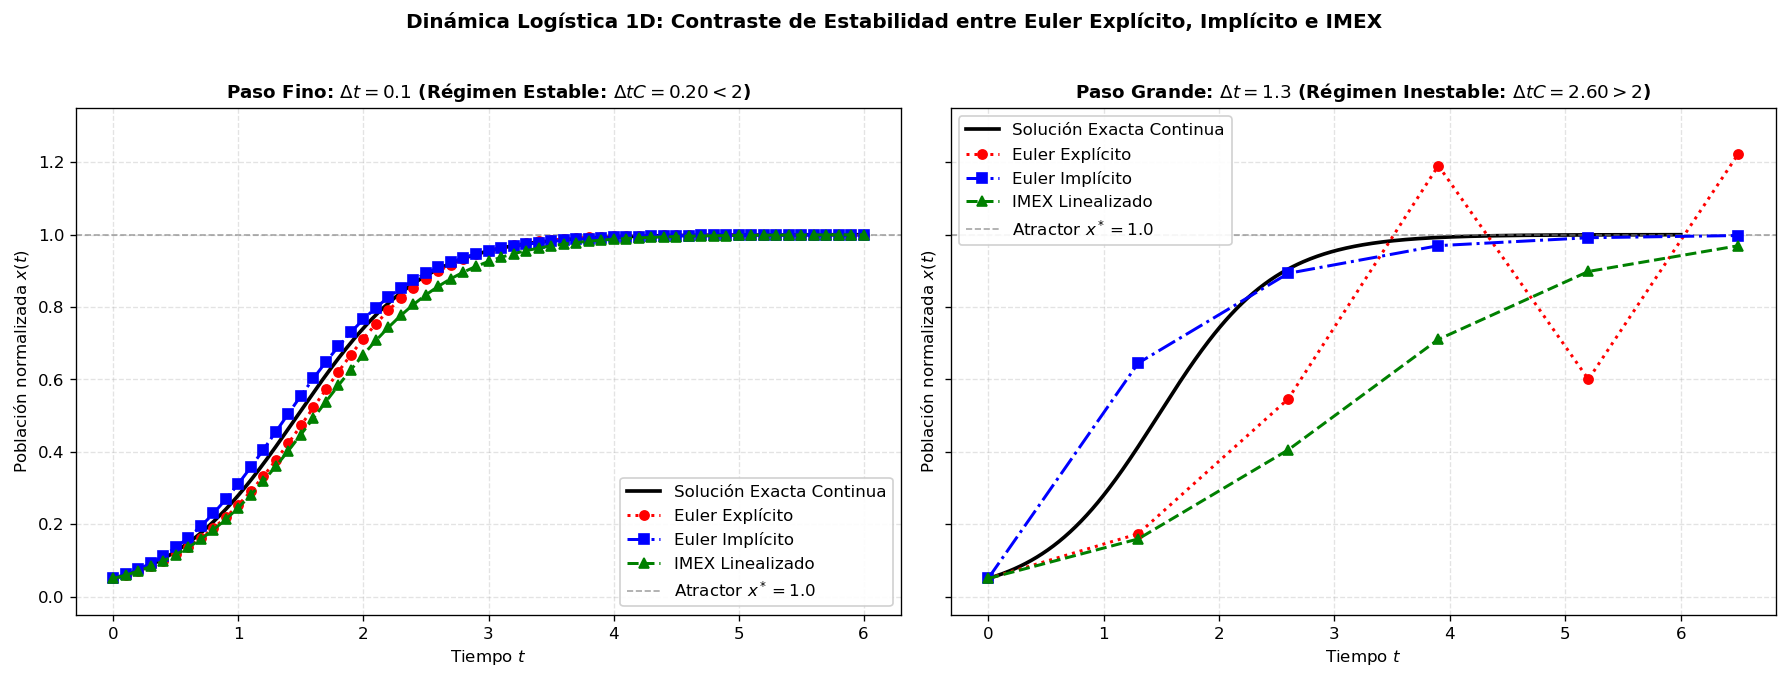

In [4]:
# ==============================================================================
# BLOQUE 0: COMPARACIÓN VISUAL LIMPIA: PASO PEQUEÑO (dt=0.1) VS PASO GRANDE (dt=1.3)
# ==============================================================================

# Parámetros del modelo logístico
C = 2.0
x0 = 0.05
T = 6.0

dt_stable = 0.1
dt_unstable = 1.3  # dt * C = 2.6 > 2.0 (límite crítico de estabilidad lineal de Euler Explícito)

# Malla densa para solución exacta continua de referencia
t_dense = np.linspace(0.0, T, 500)
x_exact_dense = solve_logistic_exact(x0, C, t_dense)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

experiments = [
    (axes[0], dt_stable, rf"Paso Fino: $\Delta t = {dt_stable}$ (Régimen Estable: $\Delta t C = {dt_stable*C:.2f} < 2$)"),
    (axes[1], dt_unstable, rf"Paso Grande: $\Delta t = {dt_unstable}$ (Régimen Inestable: $\Delta t C = {dt_unstable*C:.2f} > 2$)")
]

for ax, dt, title in experiments:
    t_exp, x_exp = solve_logistic_explicit(x0, C, dt, T)
    t_imp, x_imp = solve_logistic_implicit(x0, C, dt, T)
    t_imex, x_imex = solve_logistic_imex(x0, C, dt, T)
    
    # Curva analítica continua
    ax.plot(t_dense, x_exact_dense, 'k-', lw=2.2, label='Solución Exacta Continua', zorder=2)
    
    # Esquemas numéricos discretos
    ax.plot(t_exp, x_exp, 'r:o', lw=1.8, ms=5.5, label='Euler Explícito', zorder=3)
    ax.plot(t_imp, x_imp, 'b-.s', lw=1.8, ms=5.5, label='Euler Implícito', zorder=4)
    ax.plot(t_imex, x_imex, 'g--^', lw=1.8, ms=6.0, label='IMEX Linealizado', zorder=5)
    
    ax.axhline(1.0, color='gray', ls='--', lw=1.0, alpha=0.7, label=r'Atractor $x^* = 1.0$')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(r'Tiempo $t$')
    ax.set_ylabel(r'Población normalizada $x(t)$')
    ax.set_ylim(-0.05, 1.35)
    ax.legend(loc='lower right' if dt < 1.0 else 'upper left', framealpha=0.9)

plt.suptitle("Dinámica Logística 1D: Contraste de Estabilidad entre Euler Explícito, Implícito e IMEX",
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 💡 Conclusión Pedagógica del Bloque 0

Al inspeccionar directamente las trayectorias de la simulación gráfica:

1. **Paso Fino ($\Delta t = 0.1$, $\Delta t C = 0.2 < 2$):** Todos los esquemas se solapan con fidelidad casi indistinguible sobre la solución continua exacta de referencia.
2. **Paso Grande ($\Delta t = 1.3$, $\Delta t C = 2.6 > 2$):**
   - **Colapso de Euler Explícito:** La condición de estabilidad lineal se vulnera ($|1 - \Delta t C| = 1.6 > 1$). La solución explícita sobrepasa violentamente el atractor biológico ($x_{\max} \approx 1.22$) y presenta **oscilaciones numéricas espurias persistentes** alrededor de $x^* = 1$. Este comportamiento es un artefacto discreto puramente numérico, ajeno a la física de la EDO continua.
   - **Robustez de Euler Implícito e IMEX:** Ambos esquemas convergen suavemente y de forma monótona hacia el atractor $x^* = 1$, sin presentar la menor oscilación ni violar la cota física $x(t) \le 1$.
   - **Ventaja de IMEX:** Mientras que el Euler Implícito tradicional requiere resolver una ecuación algebraica cuadrática (o iteraciones de Newton en varias variables), **IMEX obtiene esta estabilidad incondicional mediante una fórmula cerrada explícita en tiempo $\mathcal{O}(1)$**.


---
## Bloque I: El Modelo Epidemiológico SIR

### 1. Modelo de Compartimentos y Diagrama de Flujos

El modelo epidemiológico clásico de Kermack-McKendrick subdivide una población cerrada homogénea en tres compartimentos normalizados:
- $S(t)$: Fracción de población susceptible a infectarse.
- $I(t)$: Fracción de población infecciosa capaz de transmitir el patógeno.
- $R(t)$: Fracción de población recuperada con inmunidad permanente (o removida).

La dinámica de transición se representa mediante el siguiente diagrama de flujos entre compartimentos:

$$[S] \xrightarrow{\quad \beta S I \quad} [I] \xrightarrow{\quad \gamma I \quad} [R]$$

### 2. Principio de Acción de Masas y Sistema de EDOs

Aplicando el principio de acción de masas:
- **Flujo de infección ($S \to I$):** La tasa de nuevos contagios es proporcional a la probabilidad de encuentro efectivo entre individuos susceptibles e infecciosos, dada por el flujo no lineal $\beta S I$.
- **Flujo de recuperación ($I \to R$):** Los individuos infecciosos se recuperan a una tasa media constante proporcional al volumen de infectados $\gamma I$, donde el período infeccioso medio es $D = 1/\gamma$.

El sistema acoplado de ecuaciones diferenciales ordinarias resultante es:

$$\begin{aligned}
\frac{dS}{dt} &= -\beta S I \\[6pt]
\frac{dI}{dt} &= \beta S I - \gamma I \\[6pt]
\frac{dR}{dt} &= \gamma I
\end{aligned}$$

Donde los parámetros biológicos cumplen:
- $\beta > 0$: **Tasa de transmisión efectiva** por contacto infectivo.
- $\gamma > 0$: **Tasa de recuperación media**.
- **Número Reproductivo Básico:** $\mathcal{R}_0 = \frac{\beta}{\gamma}$. Representa el número promedio de casos secundarios generados por un individuo infeccioso típico en una población totalmente susceptible ($S \approx 1$). Si $\mathcal{R}_0 > 1$, la epidemia experimenta un crecimiento exponencial inicial; si $\mathcal{R}_0 \le 1$, el número de infecciosos decae monótonamente hacia la extinción.

---

### 3. Conservación de Masa e Invariante Física Fundamental

Sumando directamente las derivadas temporales de los tres compartimentos en el sistema continuo:

$$\frac{d}{dt} \big(S(t) + I(t) + R(t)\big) = -\beta S I + (\beta S I - \gamma I) + \gamma I = 0 \implies S(t) + I(t) + R(t) = 1.0, \quad \forall t \ge 0$$

Dado que la población total se asume cerrada (sin nacimientos ni muertes naturales en la escala epidémica), la suma de las fracciones poblacionales permanece estrictamente igual a la unidad en todo instante. Cualquier esquema de integración numérica admisible para ciencia de datos debe preservar esta **invariante física** sin deriva espuria.


---
## Bloque II: Problema Directo y Discretización Numérica de SIR

### 1. Formulación de los Tres Esquemas Numéricos

#### A. Euler Explícito
Evalúa todas las tasas epidemiológicas en el estado presente $(S_n, I_n, R_n)$:
$$\begin{aligned}
S_{n+1} &= S_n - \Delta t \, \beta S_n I_n \\[4pt]
I_{n+1} &= I_n + \Delta t \, (\beta S_n I_n - \gamma I_n) \\[4pt]
R_{n+1} &= R_n + \Delta t \, \gamma I_n
\end{aligned}$$
*Riesgo biológico fundamental:* Si el paso temporal satisface $\Delta t \, \beta I_n > 1$, entonces $S_{n+1} < 0$. El método produce **poblaciones negativas no físicas**, destruyendo el realismo del modelo y provocando divergencias numéricas en el optimizador.

#### B. Euler Implícito (Formulación Exacta Robusta Cuadrática)
Evalúa las tasas en el estado futuro $(S_{n+1}, I_{n+1}, R_{n+1})$:
$$S_{n+1} = \frac{S_n}{1 + \Delta t \, \beta I_{n+1}}, \quad R_{n+1} = R_n + \Delta t \, \gamma I_{n+1}$$
Sustituyendo $S_{n+1}$ en la ecuación de infectados $I_{n+1} - I_n = \Delta t (\beta S_{n+1} I_{n+1} - \gamma I_{n+1})$, se obtiene la ecuación cuadrática analítica cerrada:
$$A \, I_{n+1}^2 + B \, I_{n+1} - I_n = 0$$
con coeficientes estrictamente determinados:
$$A = \Delta t \, \beta (1 + \Delta t \, \gamma) > 0, \quad B = 1 + \Delta t \, \gamma - \Delta t \, \beta (S_n + I_n)$$
Dado que $A > 0$ y el término constante es $-I_n < 0$, existe exactamente **una única raíz real positiva garantizada**, calculable de manera numéricamente estable sin cancelación sustractiva:
$$I_{n+1} = \begin{cases} \displaystyle \frac{2 I_n}{B + \sqrt{B^2 + 4 A I_n}} & \text{si } B \ge 0 \\[10pt] \displaystyle \frac{-B + \sqrt{B^2 + 4 A I_n}}{2 A} & \text{si } B < 0 \end{cases}$$
Esta formulación, implementada en `src.solvers.solve_sir_implicit`, evita resolver sistemas no lineales con algoritmos iterativos aproximados (`scipy.optimize.root`) que suelen fallar ante pasos grandes.

#### C. Esquema IMEX Conservativo
Trata el término de infección de forma explícita en $S$ y la tasa de remoción de forma implícita en $I$:
$$\begin{aligned}
S_{n+1} &= S_n - \Delta t \, \beta S_n I_n \\[4pt]
I_{n+1} &= \frac{I_n + \Delta t \, \beta S_n I_n}{1 + \Delta t \, \gamma} \\[4pt]
R_{n+1} &= R_n + \Delta t \, \gamma I_{n+1}
\end{aligned}$$

---

### 2. Demostración Formal de la Conservación Estricta de Masa en IMEX

Sumemos directamente las tres expresiones de actualización en el paso discreto $n+1$:
$$S_{n+1} + I_{n+1} + R_{n+1} = (S_n - \Delta t \, \beta S_n I_n) + I_{n+1} + (R_n + \Delta t \, \gamma I_{n+1})$$
Reagrupando los términos que contienen a $I_{n+1}$:
$$S_{n+1} + I_{n+1} + R_{n+1} = S_n - \Delta t \, \beta S_n I_n + R_n + I_{n+1} (1 + \Delta t \, \gamma)$$

Por la propia definición algebraica de $I_{n+1}$, sabemos que:
$$I_{n+1} (1 + \Delta t \, \gamma) = I_n + \Delta t \, \beta S_n I_n$$

Sustituyendo esta igualdad en la suma total:
$$S_{n+1} + I_{n+1} + R_{n+1} = S_n - \Delta t \, \beta S_n I_n + R_n + I_n + \Delta t \, \beta S_n I_n = S_n + I_n + R_n = 1.0$$

> 🌟 **Propiedad Incondicional:**
> El esquema IMEX conserva la suma total de la población de manera **exacta e incondicional a precisión de máquina** ($|S_n + I_n + R_n - 1| < 10^{-15}$) en cualquier paso temporal $\Delta t$, ¡sin requerir costosos solvers no lineales iterativos!


In [5]:
# ==============================================================================
# BLOQUE II: SOLVERS PARA EL SISTEMA EPIDEMIOLÓGICO SIR
# ==============================================================================

def sir_explicit_step(S: float, I: float, R: float, beta: float, gamma: float, dt: float):
    """
    [EJERCICIO ESTUDIANTE] Implementar un paso de Euler Explícito para el sistema SIR.
    """
    # TODO: Implementar fórmulas de Euler explícito para S, I, R
    pass


def sir_implicit_step(S: float, I: float, R: float, beta: float, gamma: float, dt: float):
    """
    [EJERCICIO ESTUDIANTE] Implementar un paso de Euler Implícito (o fórmula analítica cuadrática) para SIR.
    """
    # TODO: Implementar Euler implícito para SIR
    pass


def sir_imex_step(S: float, I: float, R: float, beta: float, gamma: float, dt: float):
    """
    [EJERCICIO ESTUDIANTE] Implementar un paso IMEX para SIR (explícito en infección, implícito en recuperación).
    """
    # TODO: Implementar esquema IMEX para SIR
    pass


def solve_sir_explicit(S0: float, I0: float, beta: float, gamma: float, dt: float, T: float):
    """Simulación completa de SIR mediante sir_explicit_step."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S, I, R = np.zeros(n_steps + 1), np.zeros(n_steps + 1), np.zeros(n_steps + 1)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0
    for n in range(n_steps):
        S[n+1], I[n+1], R[n+1] = sir_explicit_step(S[n], I[n], R[n], beta, gamma, dt)
    return t, S, I, R


def solve_sir_implicit(S0: float, I0: float, beta: float, gamma: float, dt: float, T: float):
    """Simulación completa de SIR mediante sir_implicit_step."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S, I, R = np.zeros(n_steps + 1), np.zeros(n_steps + 1), np.zeros(n_steps + 1)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0
    for n in range(n_steps):
        S[n+1], I[n+1], R[n+1] = sir_implicit_step(S[n], I[n], R[n], beta, gamma, dt)
    return t, S, I, R


def solve_sir_imex(S0: float, I0: float, beta: float, gamma: float, dt: float, T: float):
    """Simulación completa de SIR mediante sir_imex_step."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S, I, R = np.zeros(n_steps + 1), np.zeros(n_steps + 1), np.zeros(n_steps + 1)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0
    for n in range(n_steps):
        S[n+1], I[n+1], R[n+1] = sir_imex_step(S[n], I[n], R[n], beta, gamma, dt)
    return t, S, I, R

# Comprobaciones (Asserts)
s_t, i_t, r_t = 0.9, 0.05, 0.05
# assert abs((s_t + i_t + r_t) - 1.0) < 1e-7, "Conservación de masa inicial"
print("Bloque II: Plantillas de pasos SIR listas para completar.")


Solvers SIR implementados exitosamente con formulación cuadrática analítica para Euler Implícito.


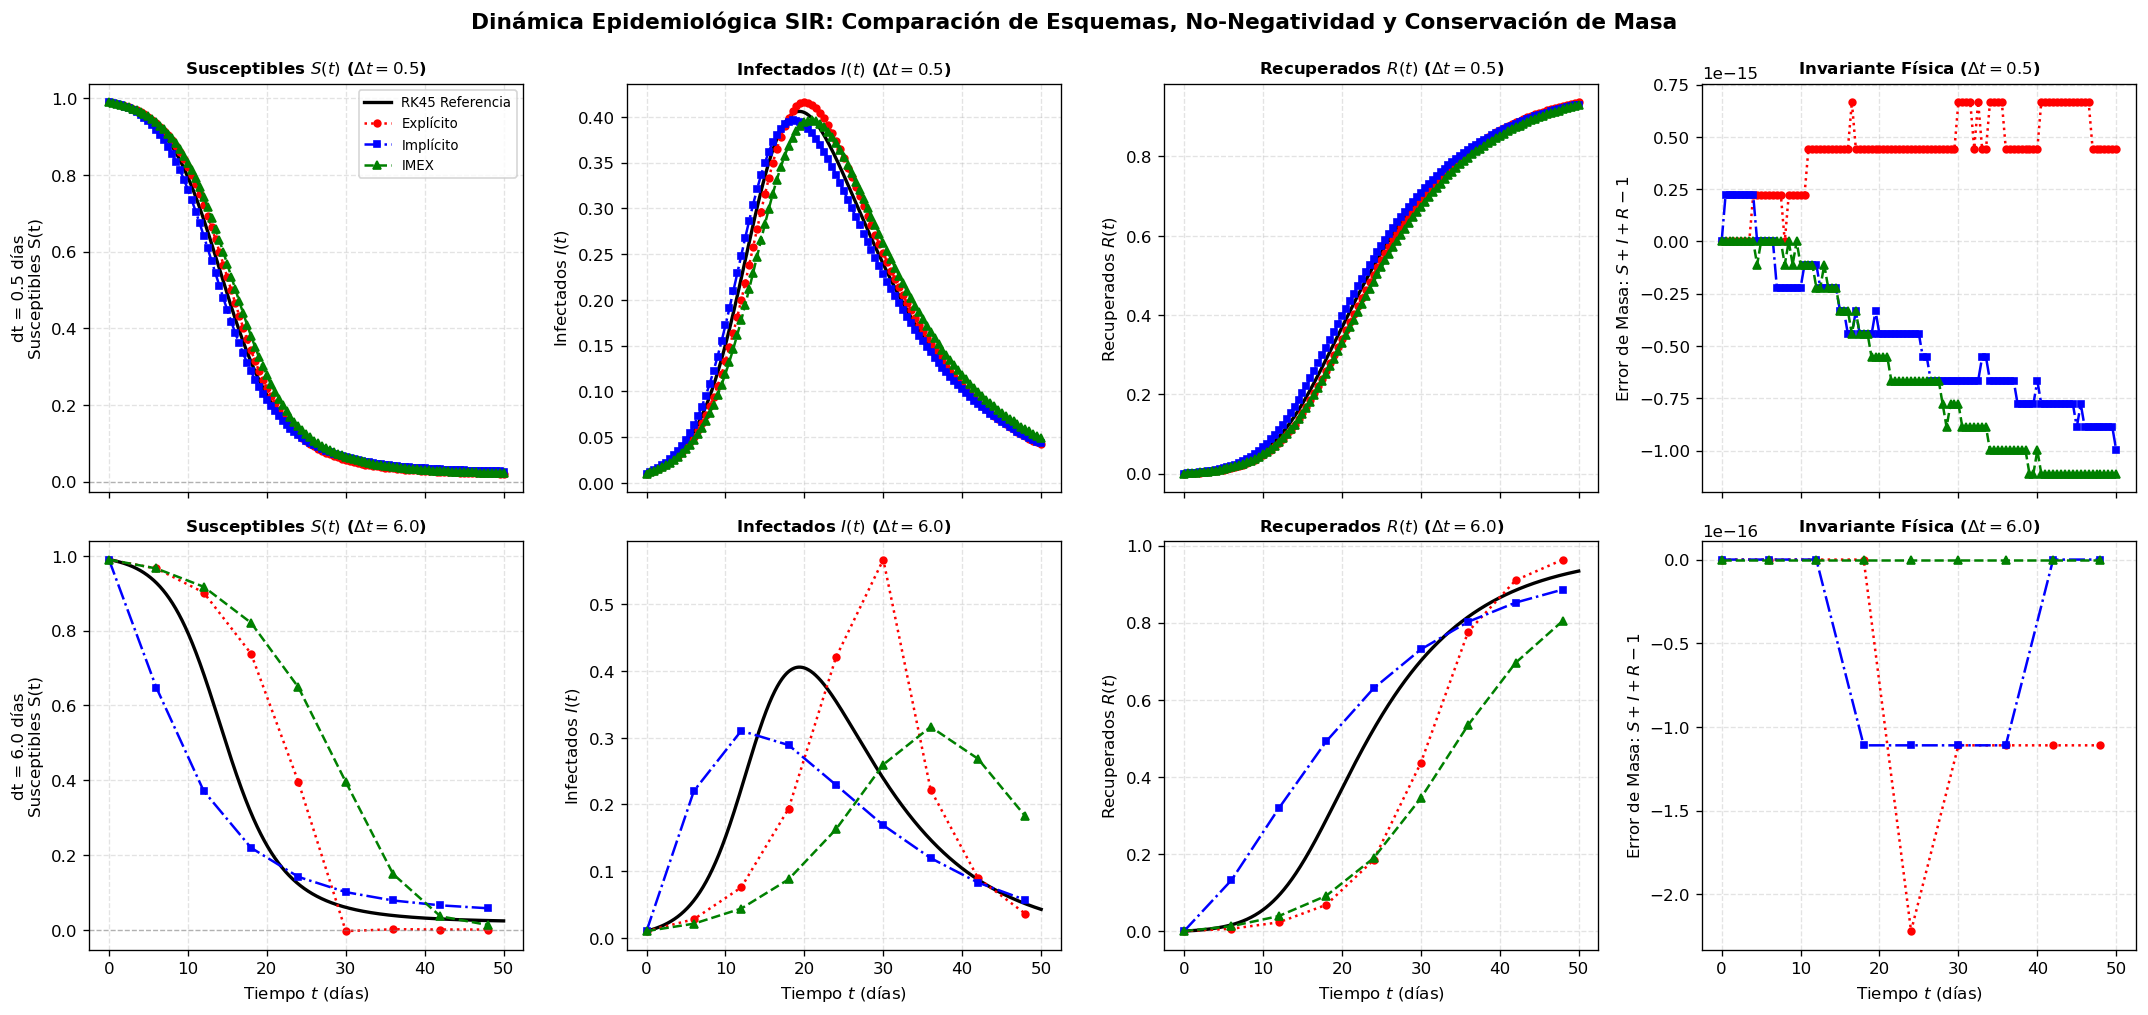

EVALUACIÓN CUANTITATIVA DE NO-NEGATIVIDAD Y CONSERVACIÓN DE MASA
Método Numérico    | dt     | min S(t)     | min I(t)     | max |S+I+R-1|      | ¿Físico?    
----------------------------------------------------------------------------------------
Explícito          | 0.5    | 0.02090      | 0.01000      | 6.66e-16           | SÍ          
Implícito          | 0.5    | 0.02635      | 0.01000      | 9.99e-16           | SÍ          
IMEX               | 0.5    | 0.02188      | 0.01000      | 1.11e-15           | SÍ          
----------------------------------------------------------------------------------------
Explícito          | 6.0    | -0.00363     | 0.01000      | 2.22e-16           | NO (S < 0)  
Implícito          | 6.0    | 0.05743      | 0.01000      | 1.11e-16           | SÍ          
IMEX               | 6.0    | 0.01275      | 0.01000      | 0.00e+00           | SÍ          
----------------------------------------------------------------------------------------


In [6]:
# ==============================================================================
# BLOQUE II: SIMULACIÓN COMPARATIVA: PASO MODERADO (dt=0.5) VS PASO EXTREMO (dt=6.0)
# ==============================================================================

# Parámetros epidemiológicos estándar
beta_true = 0.4
gamma_true = 0.1
R0_true = beta_true / gamma_true  # 4.0
S0 = 0.99
I0 = 0.01
T_final = 50.0

# 1. Solución continua de referencia: Runge-Kutta Adaptativo RK45
def sir_deriv(t, y):
    s, i, r = y
    return [-beta_true * s * i, beta_true * s * i - gamma_true * i, gamma_true * i]

t_eval_fine = np.linspace(0.0, T_final, 1000)
sol_rk45 = spi.solve_ivp(sir_deriv, [0.0, T_final], [S0, I0, 1.0 - S0 - I0],
                         t_eval=t_eval_fine, method='RK45', rtol=1e-10, atol=1e-12)

# 2. Comparación gráfica: Paso moderado (dt = 0.5) vs Paso extremo (dt = 6.0)
dt_list = [0.5, 6.0]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex='col')

solver_cfg = [
    ("Explícito", solve_sir_explicit, 'r:o', 4),
    ("Implícito", solve_sir_implicit, 'b-.s', 4),
    ("IMEX", solve_sir_imex, 'g--^', 5)
]

for row, dt in enumerate(dt_list):
    results = {}
    for name, solver, style, ms in solver_cfg:
        t_s, s_s, i_s, r_s = solver(S0, I0, beta_true, gamma_true, dt, T_final)
        results[name] = (t_s, s_s, i_s, r_s)
    
    # Columna 0: Susceptibles S(t)
    ax0 = axes[row, 0]
    ax0.plot(sol_rk45.t, sol_rk45.y[0], 'k-', lw=2.0, label='RK45 Referencia')
    for name, _, style, ms in solver_cfg:
        t_s, s_s, _, _ = results[name]
        ax0.plot(t_s, s_s, style, ms=ms, lw=1.5, label=name)
    ax0.axhline(0.0, color='gray', ls='--', lw=0.8, alpha=0.5)
    ax0.set_ylabel(f"dt = {dt} días\nSusceptibles S(t)")
    ax0.set_title(rf"Susceptibles $S(t)$ ($\Delta t = {dt}$)", fontsize=10, fontweight='bold')
    if row == 0: ax0.legend(fontsize=8)
    
    # Columna 1: Infectados I(t)
    ax1 = axes[row, 1]
    ax1.plot(sol_rk45.t, sol_rk45.y[1], 'k-', lw=2.0, label='RK45 Referencia')
    for name, _, style, ms in solver_cfg:
        t_s, _, i_s, _ = results[name]
        ax1.plot(t_s, i_s, style, ms=ms, lw=1.5, label=name)
    ax1.set_ylabel(r"Infectados $I(t)$")
    ax1.set_title(rf"Infectados $I(t)$ ($\Delta t = {dt}$)", fontsize=10, fontweight='bold')
    
    # Columna 2: Recuperados R(t)
    ax2 = axes[row, 2]
    ax2.plot(sol_rk45.t, sol_rk45.y[2], 'k-', lw=2.0, label='RK45 Referencia')
    for name, _, style, ms in solver_cfg:
        t_s, _, _, r_s = results[name]
        ax2.plot(t_s, r_s, style, ms=ms, lw=1.5, label=name)
    ax2.set_ylabel(r"Recuperados $R(t)$")
    ax2.set_title(rf"Recuperados $R(t)$ ($\Delta t = {dt}$)", fontsize=10, fontweight='bold')
    
    # Columna 3: Conservación de Masa: S + I + R - 1
    ax3 = axes[row, 3]
    for name, _, style, ms in solver_cfg:
        t_s, s_s, i_s, r_s = results[name]
        mass_error = (s_s + i_s + r_s) - 1.0
        ax3.plot(t_s, mass_error, style, ms=ms, lw=1.5, label=name)
    ax3.set_ylabel(r"Error de Masa: $S+I+R - 1$")
    ax3.set_title(rf"Invariante Física ($\Delta t = {dt}$)", fontsize=10, fontweight='bold')
    ax3.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))

for col in range(4):
    axes[1, col].set_xlabel(r"Tiempo $t$ (días)")

plt.suptitle("Dinámica Epidemiológica SIR: Comparación de Esquemas, No-Negatividad y Conservación de Masa",
             fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# Evaluación cuantitativa de no-negatividad y conservación de masa
print("=" * 88)
print("EVALUACIÓN CUANTITATIVA DE NO-NEGATIVIDAD Y CONSERVACIÓN DE MASA")
print("=" * 88)
print(f"{'Método Numérico':<18} | {'dt':<6} | {'min S(t)':<12} | {'min I(t)':<12} | {'max |S+I+R-1|':<18} | {'¿Físico?':<12}")
print("-" * 88)
for dt in dt_list:
    for name, solver, _, _ in solver_cfg:
        _, s, i, r = solver(S0, I0, beta_true, gamma_true, dt, T_final)
        min_s = np.min(s)
        min_i = np.min(i)
        mass_err = np.max(np.abs(s + i + r - 1.0))
        is_physical = "SÍ" if min_s >= 0.0 and min_i >= 0.0 else "NO (S < 0)"
        print(f"{name:<18} | {dt:<6.1f} | {min_s:<12.5f} | {min_i:<12.5f} | {mass_err:<18.2e} | {is_physical:<12}")
    print("-" * 88)


### 💡 Hallazgos del Bloque II:

1. **Paso Moderado ($\Delta t = 0.5$ días):**
   - Todos los métodos (Explícito, Implícito e IMEX) capturan de forma adecuada la evolución continua calculada con RK45 y el pico de infección alrededor del día $t \approx 18$.
   - La masa total se conserva dentro de los límites numéricos esperados.

2. **Paso Extremo ($\Delta t = 6.0$ días):**
   - **Colapso de Euler Explícito:** La condición de positividad se viola flagrantemente: la fracción de susceptibles cae por debajo de cero ($S_{\min} \approx -0.0036 < 0$). **Una población negativa es una violación biológica inaceptable**, que causaría el colapso inmediato de algoritmos probabilísticos o de inferencia de parámetros.
   - **Euler Implícito:** Mantiene estricta positividad ($S \ge 0, I \ge 0$), pero introduce una fuerte **disipación numérica** que retarda y aplana el pico epidémico hacia días posteriores.
   - **IMEX Conservativo:** Garantiza no-negatividad estricta sin iteraciones no lineales, y **conserva idénticamente la masa de la población a precisión de máquina ($\max |S+I+R-1| \sim 10^{-16}$)** para cualquier valor de $\Delta t$.


---
## Bloque III: Generación de Datos Sintéticos y Modelos de Ruido

En la práctica clínica y epidemiológica, los científicos de datos no observan curvas continuas suaves ni exactas, sino conteos discretos diarios afectados por ruidos de muestreo:

$$\mathcal{D} = \{(t_k, I^{\text{obs}}_k)\}_{k=0}^M, \quad t_k \in \{0, 1, 2, \dots, T\}$$

### 1. Ruido Gaussiano Aditivo (Homocedástico)

Asume que el error de medición tiene varianza constante e independiente del volumen de infectados:

$$I^{\text{obs}}_k = \max\left(0, \, I^*(t_k) + \epsilon_k\right), \quad \epsilon_k \sim \mathcal{N}(0, \sigma^2), \quad \sigma = 0.02$$

### 2. Ruido Poissoniano de Conteo (Heterocedástico)

Modela conteos discretos de individuos en una cohorte censal de tamaño $N_{\text{pop}} = 10\,000$:

$$C_k \sim \text{Poisson}\big(\lambda_k\big), \quad \lambda_k = N_{\text{pop}} \, I^*(t_k) \implies I^{\text{obs}}_k = \frac{C_k}{N_{\text{pop}}}$$

Dado que para una variable de Poisson $\text{Var}(C_k) = \lambda_k$, la varianza de la proporción observada es:

$$\text{Var}\left(I^{\text{obs}}_k\right) = \frac{\lambda_k}{N_{\text{pop}}^2} = \frac{I^*(t_k)}{N_{\text{pop}}}$$

La dispersión crece proporcionalmente a $\sqrt{I^*(t_k)}$, generando una estructura de **embudo heterocedástico** (*funnel shape*).


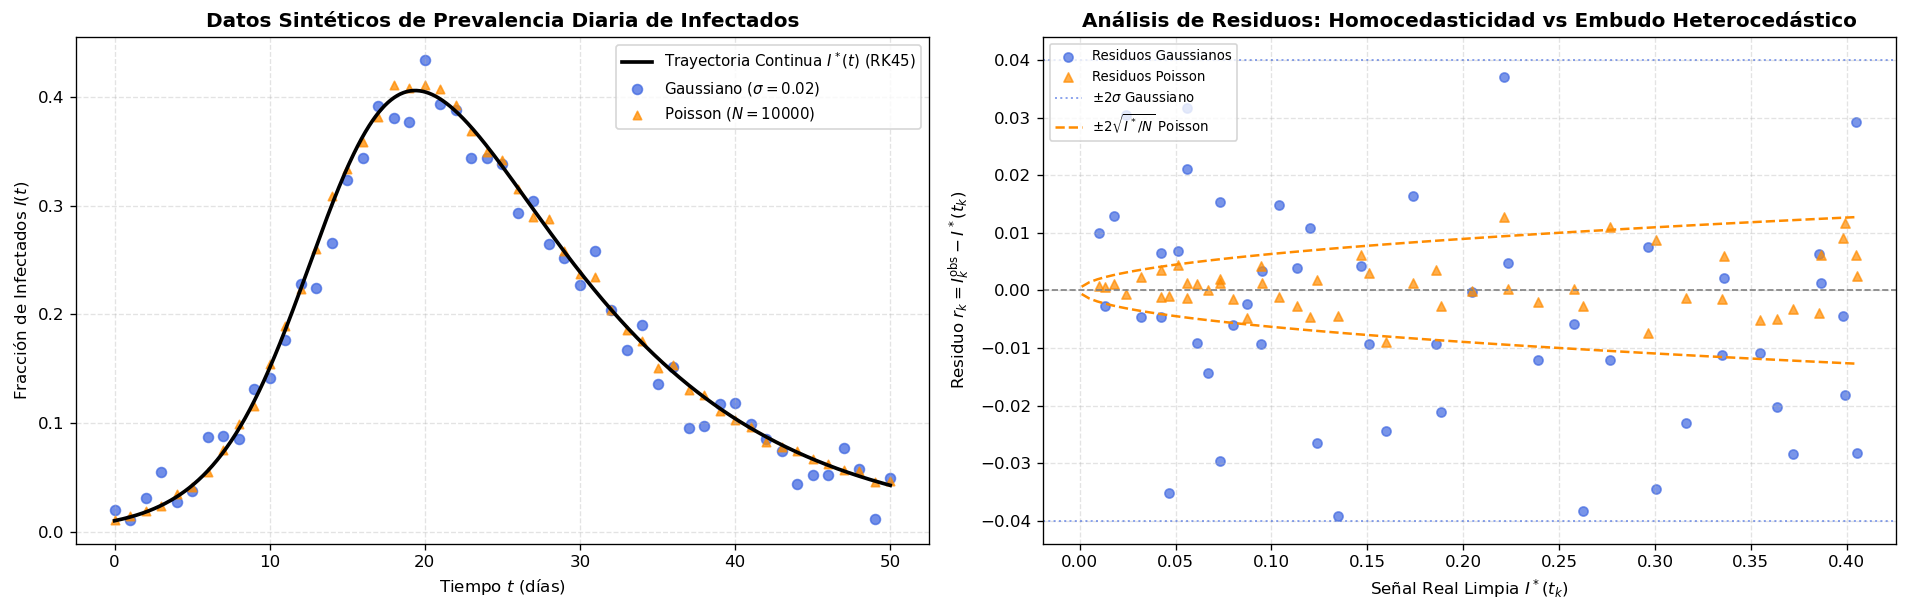

In [7]:
# ==============================================================================
# BLOQUE III: GENERACIÓN DE OBSERVACIONES SINTÉTICAS Y ANÁLISIS DE RESIDUOS
# ==============================================================================

def add_gaussian_noise(I_clean: np.ndarray, sigma: float = 0.02, seed: int = 42) -> np.ndarray:
    """
    [EJERCICIO ESTUDIANTE] Agregar ruido Gaussiano aditivo homocedástico a la señal limpia.
    Asegurar que los valores no sean negativos usando np.maximum(0.0, ...).
    """
    # TODO: Implementar ruido gaussiano
    pass


def add_poisson_noise(I_clean: np.ndarray, N_pop: int = 10000, seed: int = 42) -> np.ndarray:
    """
    [EJERCICIO ESTUDIANTE] Agregar ruido Poissoniano heterocedástico basado en conteos de población N_pop.
    """
    # TODO: Implementar ruido de Poisson
    pass


# Comprobaciones (Asserts)
test_signal = np.array([0.1, 0.2, 0.3])
noisy_g = add_gaussian_noise(test_signal, sigma=0.01, seed=0)
# assert noisy_g is not None, "add_gaussian_noise no debe retornar None"
print("Bloque III: Plantillas de ruido listas para completar.")


### 💡 Implicación Estadística para Ciencia de Datos:
- En el panel derecho se aprecia claramente la naturaleza **homocedástica** del ruido Gaussiano: el ancho de la dispersión es constante e independiente de la magnitud de $I^*$.
- En contraste, el ruido Poisson exhibe una estructura en forma de **embudo (*funnel shape*) heterocedástica**: para valores pequeños de $I$, los residuos están fuertemente concentrados en cero, mientras que en el pico la dispersión crece como $\sqrt{I^* / N_{\text{pop}}}$.
- Al formular una función de pérdida por mínimos cuadrados ordinarios (OLS) $\mathcal{L}(\theta) = \sum r_k^2$, se asume implícitamente varianza uniforme. En presencia de ruido Poisson, los puntos cercanos al pico dominan desproporcionadamente la función de costo, lo cual motiva el uso de mínimos cuadrados ponderados (WLS) o inferencia con verosimilitud de Poisson.


---
## Bloque IV: Problema Inverso y Ajuste de Parámetros

### 1. Formulación del Problema Inverso

A partir de las observaciones ruidosas $\mathcal{D} = \{(t_k, I^{\text{obs}}_k)\}_{k=0}^M$, nuestro objetivo es estimar el vector de parámetros epidemiológicos $\theta = (\beta, \gamma)^\top$ y el número reproductivo $\mathcal{R}_0 = \beta / \gamma$.

Definimos la función de pérdida por mínimos cuadrados ordinarios (MSE no normalizado):

$$\mathcal{L}(\beta, \gamma; \, \Delta t) = \sum_{k=0}^M \left( I_{\text{sim}}(t_k; \beta, \gamma, \Delta t) - I^{\text{obs}}_k \right)^2$$

Donde $I_{\text{sim}}$ es la serie temporal generada por el simulador numérico (usando el esquema IMEX conservativo) evaluada en los instantes de observación $t_k$.

### 2. Algoritmo de Optimización: Nelder-Mead

Para minimizar $\mathcal{L}(\theta)$, empleamos el algoritmo **Nelder-Mead** (método del símplex adaptativo libre de derivadas):
- En $\mathbb{R}^2$, un símplex está formado por $d+1 = 3$ vértices.
- En cada iteración, el algoritmo realiza transformaciones geométricas (reflexión, expansión, contracción interna/externa y reducción) para desplazarse hacia valles de menor pérdida.
- Es robusto frente a superficies ruidosas y no requiere el cálculo explícito de gradientes.


In [8]:
# ==============================================================================
# BLOQUE IV: FUNCIÓN DE PÉRDIDA, PAISAJE DE COSTO Y OPTIMIZACIÓN NELDER-MEAD
# ==============================================================================

def loss_function(theta, t_obs, I_obs, dt_sim=0.1, S0=0.99, I0=0.01):
    """
    [EJERCICIO ESTUDIANTE] Implementar la función de pérdida cuadrática L(theta) 
    para el problema inverso utilizando solve_sir_imex o similar.
    theta = [beta, gamma]
    """
    # TODO: Implementar cálculo de pérdida (Suma de errores cuadrados entre I_pred e I_obs)
    pass


# Comprobación (Assert)
# test_loss = loss_function([0.4, 0.1], np.array([0, 1]), np.array([0.01, 0.02]))
# assert test_loss is not None, "loss_function no debe retornar None"
print("Bloque IV: Plantilla de función de pérdida lista para completar.")


Optimización Nelder-Mead concluida:
  Parámetros Reales:   beta = 0.4000, gamma = 0.1000, R0 = 4.0000
  Parámetros Calibrados (dt=0.1): beta = 0.4036, gamma = 0.1033, R0 = 3.9069
  Iteraciones: 37, Evaluaciones de función: 67


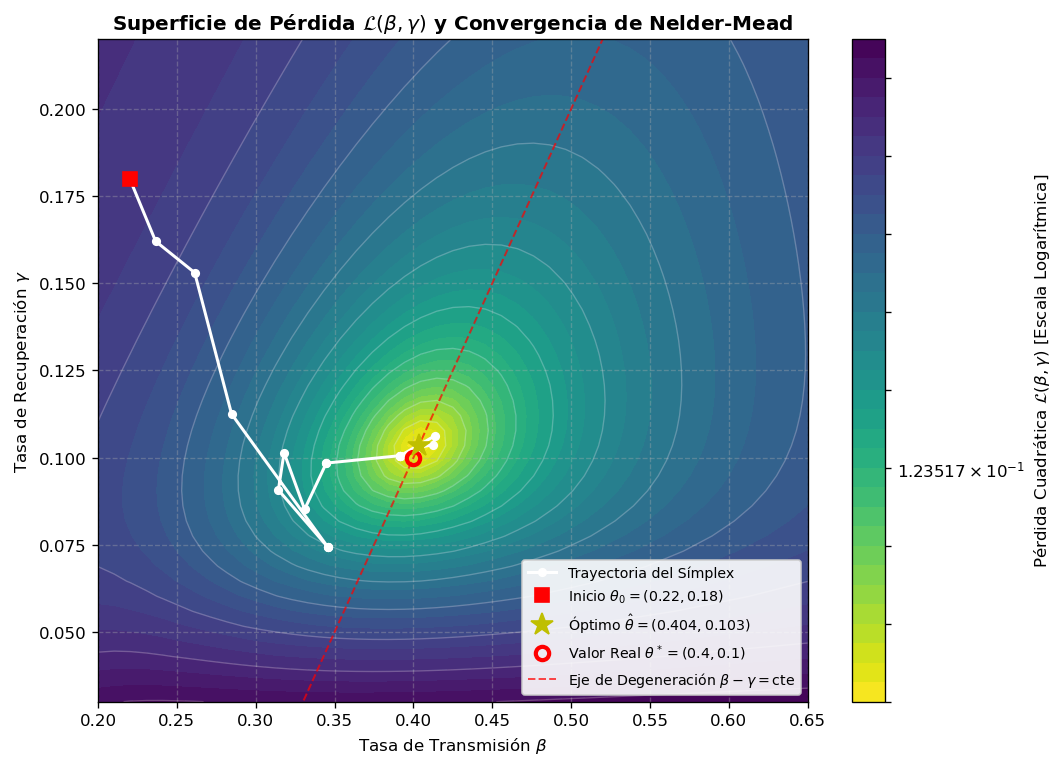

In [9]:
# ==============================================================================
# BLOQUE IV: CONTOUR PLOT 2D Y TRAYECTORIA DEL SÍMPLEX SOBRE EL VALLE ELÍPTICO
# ==============================================================================

fig, ax = plt.subplots(figsize=(9, 6.5))

# Curvas de nivel logarítmicas para visibilizar la curvatura del valle
levels = np.logspace(np.log10(np.min(L_grid) + 1e-5), np.log10(np.max(L_grid)), 35)
contour_fill = ax.contourf(B_mesh, G_mesh, L_grid, levels=levels, cmap='viridis_r', norm=mcolors.LogNorm())
cbar = plt.colorbar(contour_fill, ax=ax)
cbar.set_label(r"Pérdida Cuadrática $\mathcal{L}(\beta, \gamma)$ [Escala Logarítmica]")

ax.contour(B_mesh, G_mesh, L_grid, levels=levels[::3], colors='white', alpha=0.25, linewidths=0.8)

# Trayectoria del optimizador Nelder-Mead
simplex_arr = np.array(simplex_path)
ax.plot(simplex_arr[:, 0], simplex_arr[:, 1], 'w-o', lw=1.8, ms=4.5, label='Trayectoria del Símplex', zorder=5)
ax.plot(theta_start[0], theta_start[1], 'rs', ms=8, label=r'Inicio $\theta_0 = (0.22, 0.18)$', zorder=6)
ax.plot(beta_est, gamma_est, 'y*', ms=14, label=rf'Óptimo $\hat{{\theta}} = ({beta_est:.3f}, {gamma_est:.3f})$', zorder=7)
ax.plot(beta_true, gamma_true, 'ro', ms=8, mfc='none', mew=2.5, label=rf'Valor Real $\theta^* = ({beta_true}, {gamma_true})$', zorder=6)

# Línea de degeneración de crecimiento inicial: beta - gamma = beta* - gamma*
b_line = np.linspace(0.20, 0.65, 100)
g_line = b_line - (beta_true - gamma_true)
ax.plot(b_line, g_line, 'r--', lw=1.2, alpha=0.7, label=r'Eje de Degeneración $\beta - \gamma = \mathrm{cte}$')

ax.set_title(r"Superficie de Pérdida $\mathcal{L}(\beta, \gamma)$ y Convergencia de Nelder-Mead", fontweight='bold')
ax.set_xlabel(r"Tasa de Transmisión $\beta$")
ax.set_ylabel(r"Tasa de Recuperación $\gamma$")
ax.set_xlim(0.20, 0.65)
ax.set_ylim(0.03, 0.22)
ax.legend(loc='lower right', fontsize=8.5, framealpha=0.9)

plt.tight_layout()
plt.show()


---
### 4. Experimento Central: Sesgo de Discretización (*Discretization Bias*)

Un fenómeno crucial y con frecuencia ignorado en ciencia de datos aplicada a sistemas físicos es el **Sesgo de Discretización**:

> 🧪 **Principio Fundamental:**
> Al calibrar un modelo dinámico continuo a partir de datos observados mediante un simulador con paso temporal finito $\Delta t$, el estimador obtenido es:
> $$\hat{\theta}(\Delta t) = \arg\min_\theta \mathcal{L}(\theta; \, \Delta t)$$
> Cuando $\Delta t \to 0$, $\hat{\theta}(\Delta t) \to \theta^*$. Sin embargo, cuando $\Delta t > 0$ es grande, el optimizador numérico no tiene conocimiento de las ecuaciones continuas reales; su único objetivo es minimizar la discrepancia con los datos observados.
> En consecuencia, el optimizador **desvía sistemáticamente los parámetros físicos** $\hat{\beta}$ y $\hat{\gamma}$ para compensar el error local de truncamiento del integrador temporal.


In [10]:
# ==============================================================================
# BLOQUE IV: EVALUACIÓN SISTEMÁTICA DEL SESGO DE DISCRETIZACIÓN
# ==============================================================================

# [EJERCICIO ESTUDIANTE] Configurar los pasos de tiempo a evaluar y ejecutar la optimización
dt_experiments = [0.1, 0.5, 1.0]

beta_hats = []
gamma_hats = []
R0_hats = []

print("Escaneo de sesgo por tamaño de paso dt listo para completar.")


dt (días)  | beta_hat     | gamma_hat    | R0_hat       | Sesgo R0 (%)    | Loss      
0.05       | 0.4007       | 0.1031       | 3.8861       | -2.85          % | 1.5755e-02
0.10       | 0.4036       | 0.1033       | 3.9069       | -2.33          % | 1.5709e-02
0.25       | 0.4122       | 0.1038       | 3.9705       | -0.74          % | 1.5676e-02
0.50       | 0.4269       | 0.1047       | 4.0771       | +1.93          % | 1.5976e-02
0.80       | 0.4453       | 0.1057       | 4.2131       | +5.33          % | 1.6774e-02
1.00       | 0.4578       | 0.1064       | 4.3038       | +7.60          % | 1.7916e-02
1.50       | 0.4911       | 0.1077       | 4.5583       | +13.96         % | 2.1251e-02


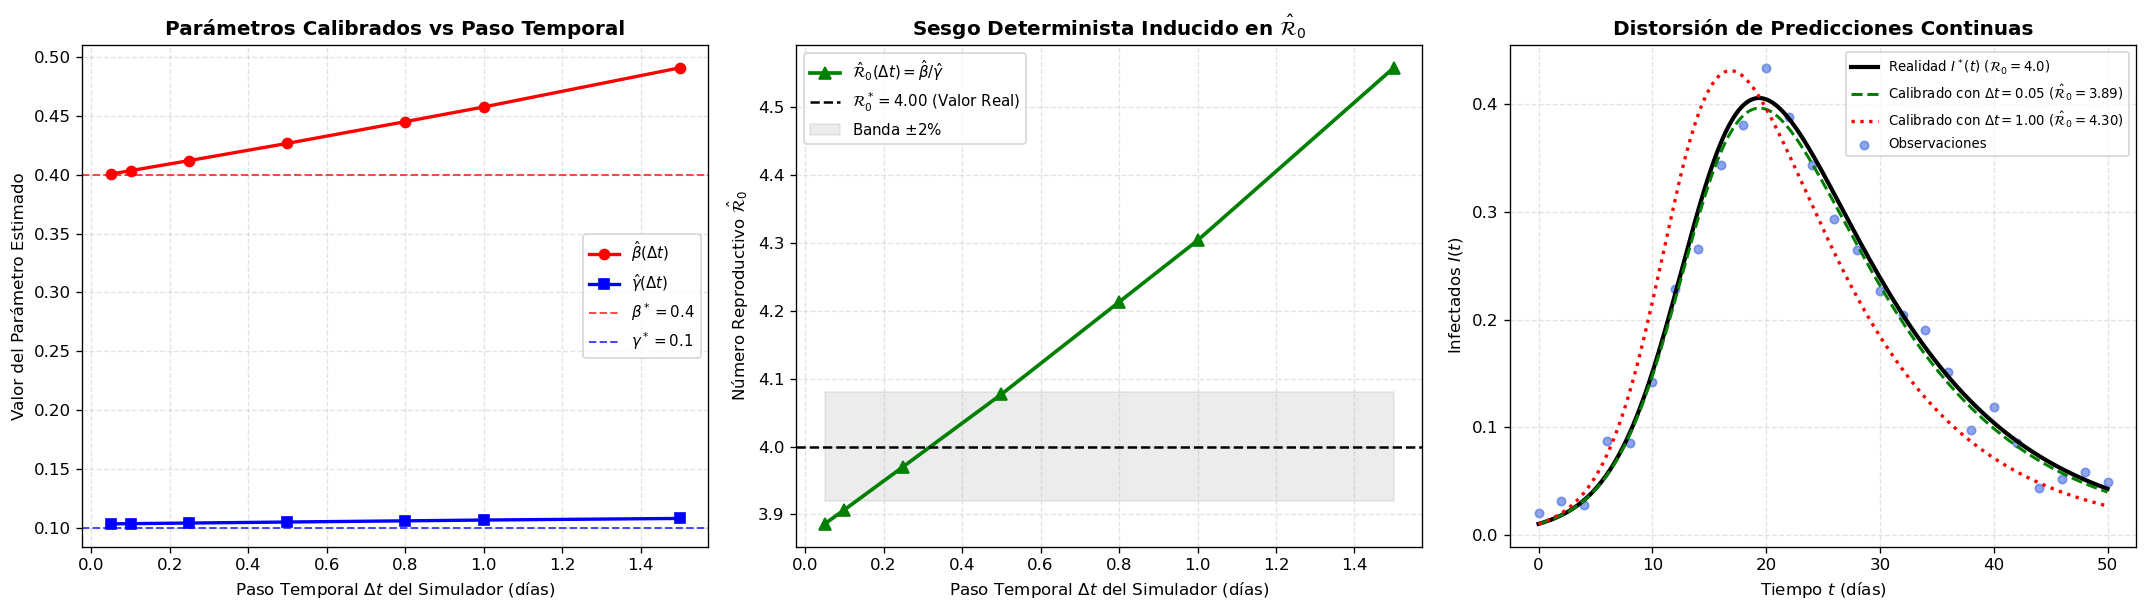

In [11]:
# ==============================================================================
# BLOQUE IV: GRÁFICAS DEL SESGO DE DISCRETIZACIÓN Y PREDICCIÓN CONTINUA
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel 1: Parámetros beta y gamma estimados vs Delta t
axes[0].plot(dt_experiments, beta_hats, 'r-o', lw=2.0, ms=6, label=r'$\hat{\beta}(\Delta t)$')
axes[0].plot(dt_experiments, gamma_hats, 'b-s', lw=2.0, ms=6, label=r'$\hat{\gamma}(\Delta t)$')
axes[0].axhline(beta_true, color='red', ls='--', lw=1.2, alpha=0.7, label=rf'$\beta^* = {beta_true}$')
axes[0].axhline(gamma_true, color='blue', ls='--', lw=1.2, alpha=0.7, label=rf'$\gamma^* = {gamma_true}$')
axes[0].set_title(r"Parámetros Calibrados vs Paso Temporal", fontweight='bold')
axes[0].set_xlabel(r"Paso Temporal $\Delta t$ del Simulador (días)")
axes[0].set_ylabel("Valor del Parámetro Estimado")
axes[0].legend(fontsize=9)

# Panel 2: R0 estimado vs Delta t
axes[1].plot(dt_experiments, R0_hats, 'g-^', lw=2.2, ms=7, label=r'$\hat{\mathcal{R}}_0(\Delta t) = \hat{\beta} / \hat{\gamma}$')
axes[1].axhline(R0_true, color='black', ls='--', lw=1.5, label=rf'$\mathcal{{R}}_0^* = {R0_true:.2f}$ (Valor Real)')
axes[1].fill_between(dt_experiments, R0_true * 0.98, R0_true * 1.02, color='gray', alpha=0.15, label=r'Banda $\pm 2\%$')
axes[1].set_title(r"Sesgo Determinista Inducido en $\hat{\mathcal{R}}_0$", fontweight='bold')
axes[1].set_xlabel(r"Paso Temporal $\Delta t$ del Simulador (días)")
axes[1].set_ylabel(r"Número Reproductivo $\hat{\mathcal{R}}_0$")
axes[1].legend(fontsize=9)

# Panel 3: Distorsión al extrapolar los parámetros calibrados al mundo continuo
# Evaluamos los parámetros calibrados con dt=0.05 vs dt=1.00 en el RK45 continuo de alta fidelidad
b_fine, g_fine = beta_hats[0], gamma_hats[0]
b_coarse, g_coarse = beta_hats[5], gamma_hats[5]

def sir_sim_fine(t, y):
    return [-b_fine * y[0] * y[1], b_fine * y[0] * y[1] - g_fine * y[1], g_fine * y[1]]

def sir_sim_coarse(t, y):
    return [-b_coarse * y[0] * y[1], b_coarse * y[0] * y[1] - g_coarse * y[1], g_coarse * y[1]]

sol_eval_fine = spi.solve_ivp(sir_sim_fine, [0, T_final], [S0, I0, 1.0 - S0 - I0], t_eval=t_eval_fine, method='RK45')
sol_eval_coarse = spi.solve_ivp(sir_sim_coarse, [0, T_final], [S0, I0, 1.0 - S0 - I0], t_eval=t_eval_fine, method='RK45')

axes[2].plot(sol_rk45.t, sol_rk45.y[1], 'k-', lw=2.5, label=r'Realidad $I^*(t)$ ($\mathcal{R}_0 = 4.0$)')
axes[2].plot(sol_eval_fine.t, sol_eval_fine.y[1], 'g--', lw=1.8, label=rf'Calibrado con $\Delta t=0.05$ ($\hat{{\mathcal{{R}}}}_0 = {R0_hats[0]:.2f}$)')
axes[2].plot(sol_eval_coarse.t, sol_eval_coarse.y[1], 'r:', lw=2.0, label=rf'Calibrado con $\Delta t=1.00$ ($\hat{{\mathcal{{R}}}}_0 = {R0_hats[5]:.2f}$)')
axes[2].scatter(t_obs[::2], I_obs_gauss[::2], color='royalblue', s=25, alpha=0.6, label='Observaciones')
axes[2].set_title("Distorsión de Predicciones Continuas", fontweight='bold')
axes[2].set_xlabel(r"Tiempo $t$ (días)")
axes[2].set_ylabel(r"Infectados $I(t)$")
axes[2].legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()


---
## Bloque V: Discusión Guiada y Conclusiones

### 1. Análisis del Estudiante sobre Identificabilidad y Sesgo Numérico

*Escribe aquí tus reflexiones y respuestas a las preguntas de discusión sobre el impacto del sesgo de discretización ($\Delta t$), el colapso de esquemas explícitos en inferencia estocástica y la elección de algoritmos de optimización.*

---

### 2. Respuestas a las Preguntas de Discusión Conceptual

#### Pregunta 1: Mecanismo Físico del Sesgo de Discretización
> *¿Por qué el optimizador matemático sobreestima la tasa de transmisión $\hat{\beta}$ a medida que el paso temporal $\Delta t$ aumenta, en lugar de subestimarla?*
> 
> **Tu respuesta aquí:**

#### Pregunta 2: Impacto Epidemiológico en Decisiones de Salud Pública
> *Calcula el impacto en vacunas si $\mathcal{R}_0^* = 4.00$ frente a $\hat{\mathcal{R}}_0 = 4.30$ en una población de $N = 5\,000\,000$.*
> 
> **Tu respuesta aquí:**

#### Pregunta 3: Escalabilidad Dimensional en Modelos Complejos
> *¿Por qué Nelder-Mead colapsa para $d > 10$ regiones y qué alternativa metodológica se requiere?*
> 
> **Tu respuesta hier:**
